# LHS Random Online Experiment

Queue-backed Latin-hypercube random campaign using the shared optimization backbone.

This notebook is the model-free comparison baseline for `notebooks/bo_online_experiment.ipynb`: `OptimizerLHSRandom` uses one deterministic Latin-hypercube sequence over the same sampled continuous candidate pool and evaluation settings.


In [1]:
from __future__ import annotations

from pathlib import Path
from datetime import datetime, timezone
import sys
import importlib
import json

import numpy as np
import pandas as pd
import yaml

CWD = Path.cwd().resolve()
if (CWD / 'src').exists():
    REPO_ROOT = CWD
elif (CWD.parent / 'src').exists():
    REPO_ROOT = CWD.parent
else:
    raise RuntimeError(f'Cannot locate repo root from cwd={CWD}')

SRC = REPO_ROOT / 'src'
if str(SRC) in sys.path:
    sys.path.remove(str(SRC))
sys.path.insert(0, str(SRC))

importlib.invalidate_caches()
for mod in [m for m in list(sys.modules) if m == 'optimization' or m.startswith('optimization.') or m == 'simulation' or m.startswith('simulation.')]:
    del sys.modules[mod]

from optimization import (
    BCLFOptimizationSpec,
    ContinuousCandidateSpace,
    ExperimentRecorder,
    OptimizerLHSRandom,
    ServerQueueSimulator,
    ReplaySimulator,
    BCLFDataset,
)
from simulation.result_store import FilesystemResultStore, BandpassFilterNamingStrategy


In [2]:
# Core runtime switches
RUN_ONLINE = True  # Set False to inspect/plot without submitting queue jobs.
SIMULATOR_BACKEND = 'server'  # 'server' or 'replay'
RESUME_IF_CHECKPOINT = True
RESET_CHECKPOINT = False  # If True, reset each configured seed checkpoint before running.
CLEAR_QUEUE_ARTIFACTS_ON_RESET = True
DEBUG_VERBOSE = True
DEBUG_PRINT_EVERY = 1

# Campaign controls
SEEDS = [0, 1, 2, 3, 4]
TOTAL_BUDGET = 80
POOL_SIZE = 1500
METHOD_LABEL = 'lhs_random'

# Paths
CONFIG_PATH = REPO_ROOT / 'configs' / 'filter_bnn_online_uaw_uaw.yaml'
REPLAY_DATASET_PATH = REPO_ROOT / 'data' / 'filter_bnn_online_uaw_uaw_dataset.pkl'
OUTPUT_DIR = REPO_ROOT / 'experiments' / 'lhs_online_general'
CACHE_DIR = REPO_ROOT / 'data' / 'bandpass_coupled_line_filter_export' / 'ext'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Queue + template settings
QUEUE_ROOT = REPO_ROOT / 'queue'
TEMPLATE_NAME = 'bclf_template_v1'
DESIGN_NAME = None
SETUP_NAME = None
SWEEP_NAME = None
UNIT_MAP = {
    'L': 'mm', 'L1': 'mm', 'L2': 'mm',
    'W': 'mm', 'W1': 'mm', 'W2': 'mm',
    'S1': 'mm', 'S2': 'mm',
}

print('repo root:', REPO_ROOT)
print('config:', CONFIG_PATH, 'exists=', CONFIG_PATH.exists())
print('output:', OUTPUT_DIR)
print('campaign_summary:', OUTPUT_DIR / 'campaign_summary.csv')
print('method:', METHOD_LABEL)
print('run_online:', RUN_ONLINE)
print('simulator_backend:', SIMULATOR_BACKEND)
print('seeds:', SEEDS)
print('target_trials:', TOTAL_BUDGET)


repo root: /home/zhanghf/projects/vector
config: /home/zhanghf/projects/vector/configs/filter_bnn_online_uaw_uaw.yaml exists= True
output: /home/zhanghf/projects/vector/experiments/lhs_online_general
campaign_summary: /home/zhanghf/projects/vector/experiments/lhs_online_general/campaign_summary.csv
method: lhs_random
run_online: True
simulator_backend: server
seeds: [0, 1, 2, 3, 4]
target_trials: 80


In [3]:
if not CONFIG_PATH.exists():
    raise FileNotFoundError(f'CONFIG_PATH does not exist: {CONFIG_PATH}')

with CONFIG_PATH.open('r', encoding='utf-8') as f:
    cfg = yaml.safe_load(f)

variable_order = list(BCLFDataset.DEFAULT_FILTER_VARIABLE_ORDER)

reg_min = list(cfg['data']['regularization']['min'])
reg_max = list(cfg['data']['regularization']['max'])
if len(reg_min) == len(variable_order) + 1:
    reg_min = reg_min[:len(variable_order)]
    reg_max = reg_max[:len(variable_order)]
if len(reg_min) != len(variable_order):
    raise ValueError(f'Regularization dimension mismatch: len(min)={len(reg_min)} variable_order={len(variable_order)}')

variable_bounds = {
    name: (float(reg_min[i]), float(reg_max[i]))
    for i, name in enumerate(variable_order)
}

spec = BCLFOptimizationSpec(
    passband_ghz=(4.8, 5.4),
    lower_stopband_ghz=(3.6, 4.4),
    upper_stopband_ghz=(5.8, 8.7),
    min_passband_s21_db=-5.0,
    max_passband_s11_db=-7.0,
    max_stopband_s21_db=-15.0,
    s11_weight=0.5,
    stopband_weight=0.5,
)

display(pd.DataFrame({
    'variable': variable_order,
    'low': [variable_bounds[k][0] for k in variable_order],
    'high': [variable_bounds[k][1] for k in variable_order],
}))



,variable,low,high
0,L,7.70,7.90
1,L1,8.00,8.20
2,L2,7.80,8.00
3,W,0.90,1.10
4,W1,0.70,0.90
5,W2,0.90,1.10
6,S1,0.13,0.16
7,S2,0.55,0.60


In [4]:

def campaign_summary_path() -> Path:
    return OUTPUT_DIR / 'campaign_summary.csv'


def run_id_for_seed(seed: int) -> str:
    return f'lhs_online_general_seed{int(seed)}'


def checkpoint_for_seed(seed: int) -> Path:
    return OUTPUT_DIR / f'{run_id_for_seed(seed)}.checkpoint.json'


def target_trial_count() -> int:
    return int(TOTAL_BUDGET)


def _cleanup_queue_artifacts_for_run(queue_root: Path, run_id: str) -> dict[str, int]:
    """Remove stale queue artifacts matching run_id_itXXXX so a reset starts truly fresh."""
    removed = {'pending': 0, 'running': 0, 'done': 0, 'failed': 0}
    for state in ('pending', 'running', 'done', 'failed'):
        state_dir = queue_root / state
        if not state_dir.exists():
            continue
        suffix = '.result.json' if state in ('done', 'failed') else '.json'
        for path in state_dir.glob(f'{run_id}_it*{suffix}'):
            path.unlink(missing_ok=True)
            removed[state] += 1
    return removed


def _load_checkpoint_payload(seed: int) -> dict | None:
    checkpoint_path = checkpoint_for_seed(seed)
    if not checkpoint_path.exists():
        return None
    return json.loads(checkpoint_path.read_text(encoding='utf-8'))


def _checkpoint_history(seed: int) -> list[dict]:
    payload = _load_checkpoint_payload(seed)
    if payload is None:
        return []
    history = payload.get('history', [])
    return history if isinstance(history, list) else []


def effective_seed_for_rerun(seed: int) -> int:
    payload = _load_checkpoint_payload(seed)
    if payload is None or RESET_CHECKPOINT:
        return int(seed)
    checkpoint_seed = payload.get('seed')
    if checkpoint_seed is None:
        return int(seed)
    return int(checkpoint_seed)


def is_seed_completed(seed: int) -> bool:
    if RESET_CHECKPOINT:
        return False
    return len(_checkpoint_history(seed)) >= target_trial_count()


def _history_frame(seed: int, history: list[dict]) -> pd.DataFrame:
    hist = pd.DataFrame(history)
    if hist.empty:
        return hist
    hist = hist.copy()
    hist['seed'] = int(seed)
    if 'iteration' in hist:
        hist['iteration'] = pd.to_numeric(hist['iteration'], errors='coerce')
        hist = hist[np.isfinite(hist['iteration'])].copy()
        hist['iteration'] = hist['iteration'].astype(int)
        hist = hist.sort_values('iteration').reset_index(drop=True)
    return hist


def _first_feasible_iteration(history_df: pd.DataFrame) -> int | None:
    if history_df.empty or 'feasible' not in history_df or 'iteration' not in history_df:
        return None
    feasible_idx = history_df.index[history_df['feasible'] == True].tolist()  # noqa: E712
    return int(history_df.loc[feasible_idx[0], 'iteration']) if feasible_idx else None


def _best_objective_from_history(history_df: pd.DataFrame) -> float:
    if history_df.empty:
        return float('nan')
    if 'best_so_far' in history_df:
        best = pd.to_numeric(history_df['best_so_far'], errors='coerce')
        if np.isfinite(best).any():
            return float(np.nanmin(best))
    if 'objective' in history_df:
        objective = pd.to_numeric(history_df['objective'], errors='coerce')
        if np.isfinite(objective).any():
            return float(np.nanmin(objective))
    return float('nan')


def _cache_hit_ratio(history_df: pd.DataFrame) -> float:
    if history_df.empty or 'cache_hit' not in history_df:
        return float('nan')
    return float(history_df['cache_hit'].fillna(False).astype(bool).mean())


def _runtime_value(history_df: pd.DataFrame, column: str) -> float:
    if history_df.empty or column not in history_df:
        return float('nan')
    values = pd.to_numeric(history_df[column], errors='coerce')
    finite = values[np.isfinite(values)]
    return float(finite.iloc[-1]) if len(finite) else float('nan')


def _summary_row_for_seed(seed: int, status: str, history_df: pd.DataFrame) -> dict:
    run_id = run_id_for_seed(seed)
    return {
        'seed': int(seed),
        'run_id': run_id,
        'method': METHOD_LABEL,
        'status': status,
        'num_trials': int(len(history_df)),
        'best_objective': _best_objective_from_history(history_df),
        'first_feasible_iteration': _first_feasible_iteration(history_df),
        'cache_hit_ratio': _cache_hit_ratio(history_df),
        'runtime_engine_sec': _runtime_value(history_df, 't_engine_cum_sec'),
        'runtime_sim_sec': _runtime_value(history_df, 't_simulator_cum_sec'),
        'json': str(OUTPUT_DIR / f'{run_id}.json'),
        'csv': str(OUTPUT_DIR / f'{run_id}.csv'),
        'checkpoint': str(checkpoint_for_seed(seed)),
        'updated_at': datetime.now(timezone.utc).isoformat(),
    }


def load_campaign_summary(path: Path | None = None) -> pd.DataFrame:
    path = campaign_summary_path() if path is None else Path(path)
    if path.exists():
        df = pd.read_csv(path)
        if 'seed' in df.columns:
            df = df.sort_values('seed').reset_index(drop=True)
        return df
    return pd.DataFrame(columns=[
        'seed', 'run_id', 'method', 'status', 'num_trials', 'best_objective',
        'first_feasible_iteration', 'cache_hit_ratio', 'runtime_engine_sec',
        'runtime_sim_sec', 'json', 'csv', 'checkpoint', 'updated_at',
    ])


def upsert_campaign_row(row: dict, path: Path | None = None) -> pd.DataFrame:
    path = campaign_summary_path() if path is None else Path(path)
    df = load_campaign_summary(path)
    seed = int(row['seed'])
    if 'seed' in df.columns and (df['seed'] == seed).any():
        for key, value in row.items():
            df.loc[df['seed'] == seed, key] = value
    else:
        df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)
    df = df.sort_values('seed').reset_index(drop=True)
    path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(path, index=False)
    return df


def _progress_debug_callback(trial: dict, history: list[dict]) -> None:
    if not DEBUG_VERBOSE:
        return
    iteration = int(trial.get('iteration', -1))
    if DEBUG_PRINT_EVERY > 1 and iteration % int(DEBUG_PRINT_EVERY) != 0:
        return
    print(
        '[Optimizer]',
        f"iter={iteration:04d}",
        f"phase={trial.get('phase')}",
        f"obj={trial.get('objective')}",
        f"best={trial.get('best_so_far')}",
        f"status={trial.get('simulation_status')}",
        f"cache_hit={trial.get('cache_hit')}",
        f"job_id={trial.get('job_id')}",
    )
    sd = trial.get('selection_debug')
    if isinstance(sd, dict):
        mode = sd.get('mode')
        err = sd.get('select_error') or sd.get('fit_error')
        print('[SelectionDebug]', f"mode={mode}", f"error={err}")


def build_optimizer(seed: int) -> OptimizerLHSRandom:
    run_id = run_id_for_seed(seed)
    checkpoint_path = checkpoint_for_seed(seed)
    optimizer_seed = effective_seed_for_rerun(seed)

    if RESET_CHECKPOINT:
        if checkpoint_path.exists():
            checkpoint_path.unlink()
        if CLEAR_QUEUE_ARTIFACTS_ON_RESET:
            removed = _cleanup_queue_artifacts_for_run(QUEUE_ROOT, run_id)
            print('[ResetCleanup]', f'run_id={run_id}', removed)

    candidate_space = ContinuousCandidateSpace(
        variable_order=variable_order,
        variable_bounds=variable_bounds,
        pool_size=POOL_SIZE,
        seed=optimizer_seed,
        resolution=0.01,
    )

    if SIMULATOR_BACKEND == 'server':
        result_store = FilesystemResultStore(
            root_dir=CACHE_DIR,
            naming_strategy=BandpassFilterNamingStrategy(),
            port_num=2,
        )
        simulator = ServerQueueSimulator(
            queue_root=str(QUEUE_ROOT),
            variable_order=variable_order,
            unit_map=UNIT_MAP,
            template_name=TEMPLATE_NAME,
            port_num=2,
            result_store=result_store,
            design_name=DESIGN_NAME,
            setup_name=SETUP_NAME,
            sweep_name=SWEEP_NAME,
            metrics_to_extract=['max_s11_db', 'min_s21_db'],
            run_id=run_id,
            mm_resolution=0.01,
            verbose=DEBUG_VERBOSE,
        )
    elif SIMULATOR_BACKEND == 'replay':
        freq_cfg = cfg['data']['freqs']
        freqs = np.arange(freq_cfg['min'], freq_cfg['max'], freq_cfg['step'], dtype=float)
        replay_dataset = BCLFDataset.from_pickle(REPLAY_DATASET_PATH, freqs=freqs)
        simulator = ReplaySimulator(dataset=replay_dataset)
    else:
        raise ValueError(f'Unsupported SIMULATOR_BACKEND={SIMULATOR_BACKEND}. Use server or replay.')

    optimizer = OptimizerLHSRandom(
        candidate_space=candidate_space,
        simulator=simulator,
        optimization_spec=spec,
        recorder=ExperimentRecorder(output_dir=OUTPUT_DIR),
        budget=TOTAL_BUDGET,
        seed=optimizer_seed,
        run_id=run_id,
        checkpoint_path=checkpoint_path,
        resume=(RESUME_IF_CHECKPOINT and checkpoint_path.exists()),
        progress_callback=_progress_debug_callback,
    )
    return optimizer



In [5]:
run_results = []
seed_history_frames = []
history_df = pd.DataFrame()
run_result = None
campaign_summary_df = pd.DataFrame()

if RUN_ONLINE:
    campaign_summary_df = load_campaign_summary()
    print('target_trials:', target_trial_count())
    print('campaign seeds:', SEEDS)

    for seed in SEEDS:
        seed = int(seed)
        checkpoint_path = checkpoint_for_seed(seed)
        checkpoint_history = _checkpoint_history(seed)
        checkpoint_df = _history_frame(seed, checkpoint_history)

        if is_seed_completed(seed):
            print(f'[Campaign] seed={seed} completed; skipping ({len(checkpoint_df)}/{target_trial_count()} trials).')
            campaign_summary_df = upsert_campaign_row(_summary_row_for_seed(seed, 'completed', checkpoint_df))
            seed_history_frames.append(checkpoint_df)
            history_df = checkpoint_df
            continue

        status_label = 'resuming' if checkpoint_path.exists() and len(checkpoint_df) else 'starting'
        optimizer_seed = effective_seed_for_rerun(seed)
        print(f'[Campaign] seed={seed} optimizer_seed={optimizer_seed} {status_label}; checkpoint={checkpoint_path}')
        optimizer = build_optimizer(seed)
        print('checkpoint_path:', optimizer.checkpoint_path, 'exists=', optimizer.checkpoint_path.exists())

        run_result = optimizer.run()
        run_results.append(run_result)
        history_df = pd.DataFrame(run_result.history).sort_values('iteration').reset_index(drop=True)
        history_df['seed'] = seed
        seed_history_frames.append(history_df)

        final_status = 'completed' if len(history_df) >= target_trial_count() else 'in_progress'
        campaign_summary_df = upsert_campaign_row(_summary_row_for_seed(seed, final_status, history_df))

        print('run_id:', run_result.run_id)
        print('best_objective:', run_result.state.best_objective)
        print('json:', run_result.recorder_output.json_path)
        print('csv:', run_result.recorder_output.csv_path)

    all_hist_df = (
        pd.concat([df for df in seed_history_frames if not df.empty], ignore_index=True)
        if any(not df.empty for df in seed_history_frames)
        else pd.DataFrame()
    )

    print('LHS random campaign summary:')
    display(campaign_summary_df)
    if not history_df.empty:
        display(history_df.tail(10))
else:
    all_hist_df = pd.DataFrame()
    print('RUN_ONLINE=False; set True after queue/template settings are ready.')


target_trials: 80
campaign seeds: [0, 1, 2, 3, 4]
[Campaign] seed=0 completed; skipping (80/80 trials).
[Campaign] seed=1 completed; skipping (80/80 trials).
[Campaign] seed=2 optimizer_seed=2 resuming; checkpoint=/home/zhanghf/projects/vector/experiments/lhs_online_general/lhs_online_general_seed2.checkpoint.json
checkpoint_path: /home/zhanghf/projects/vector/experiments/lhs_online_general/lhs_online_general_seed2.checkpoint.json exists= True
[ServerQueueSimulator] simulate call=1 run_id=lhs_online_general_seed2 geometry=[7.82, 8.13, 7.99, 1.02, 0.79, 0.94, 0.14, 0.59]
[ServerQueueSimulator] case_id=lhs_online_general_seed2_it0046 quantized_geometry=[7.82, 8.13, 7.99, 1.02, 0.79, 0.94, 0.14, 0.59] vars={'L': 7.82, 'L1': 8.13, 'L2': 7.99, 'W': 1.02, 'W1': 0.79, 'W2': 0.94, 'S1': 0.14, 'S2': 0.59}
[ServerQueueSimulator] enqueue: job_id=lhs_online_general_seed2_it0046 template=bclf_template_v1 output=lhs_online_general_seed2_it0046.s2p queue_root=/home/zhanghf/projects/vector/queue


[ServerQueueSimulator] wait result: case_id=lhs_online_general_seed2_it0046 status=done wait=532.053s result_json=/home/zhanghf/projects/vector/queue/done/lhs_online_general_seed2_it0046.result.json
[ServerQueueSimulator] done: case_id=lhs_online_general_seed2_it0046 touchstone=/home/zhanghf/projects/vector/data/bandpass_coupled_line_filter_export/ext/Bandpass_Coupled_Line_Filter_export_Bandpass_Coupled_Line_Filter_L_7d82_L1_8d13_L2_7d99_W_1d02_W1_0d79_W2_0d94_S1_0d14_S2_0d59.s2p elapsed=532.249s
[Optimizer] iter=0046 phase=bo obj=-3.4446496143237972 best=-16.27225582389703 status=done cache_hit=False job_id=lhs_online_general_seed2_it0046
[SelectionDebug] mode=lhs_random error=None
[ServerQueueSimulator] simulate call=2 run_id=lhs_online_general_seed2 geometry=[7.8, 8.08, 7.94, 1.08, 0.79, 1.03, 0.13, 0.56]
[ServerQueueSimulator] case_id=lhs_online_general_seed2_it0047 quantized_geometry=[7.8, 8.08, 7.94, 1.08, 0.79, 1.03, 0.13, 0.56] vars={'L': 7.8, 'L1': 8.08, 'L2': 7.94, 'W': 1.08,

,seed,run_id,method,status,num_trials,best_objective,first_feasible_iteration,cache_hit_ratio,runtime_engine_sec,runtime_sim_sec,json,csv,checkpoint,updated_at
0,0,lhs_online_general_seed0,lhs_random,completed,80,-25.141275,NaN,0.9875,2.612550,261.181061,/home/zhanghf/projects/vector/experiments/lhs_...,/home/zhanghf/projects/vector/experiments/lhs_...,/home/zhanghf/projects/vector/experiments/lhs_...,2026-05-27T01:35:42.255515+00:00
1,1,lhs_online_general_seed1,lhs_random,completed,80,-19.161885,NaN,0.1500,2.616596,37766.801787,/home/zhanghf/projects/vector/experiments/lhs_...,/home/zhanghf/projects/vector/experiments/lhs_...,/home/zhanghf/projects/vector/experiments/lhs_...,2026-05-27T01:35:42.270115+00:00
2,2,lhs_online_general_seed2,lhs_random,completed,80,-16.313817,NaN,0.1000,2.627790,49110.676843,/home/zhanghf/projects/vector/experiments/lhs_...,/home/zhanghf/projects/vector/experiments/lhs_...,/home/zhanghf/projects/vector/experiments/lhs_...,2026-05-27T07:40:30.387957+00:00
3,3,lhs_online_general_seed3,lhs_random,completed,80,-9.847343,NaN,0.1375,2.535241,36469.737143,/home/zhanghf/projects/vector/experiments/lhs_...,/home/zhanghf/projects/vector/experiments/lhs_...,/home/zhanghf/projects/vector/experiments/lhs_...,2026-05-27T17:48:24.266190+00:00
4,4,lhs_online_general_seed4,lhs_random,completed,80,-23.610561,None,0.1750,2.544871,35571.589094,/home/zhanghf/projects/vector/experiments/lhs_...,/home/zhanghf/projects/vector/experiments/lhs_...,/home/zhanghf/projects/vector/experiments/lhs_...,2026-05-28T03:41:19.978150+00:00


,iteration,step,phase,requested_geometry,geometry,geometry_normalized,objective,objective_array,constraints_array,metrics,...,t_simulator_sec,optimizer_backend,selection_debug,spec_results_metadata,_response_freqs,_response_s_params,t_iteration_sec,t_engine_cum_sec,t_simulator_cum_sec,seed
70,70,70,bo,"[7.86, 8.05, 7.88, 0.94, 0.7, 0.95, 0.15, 0.58]","[7.86, 8.05, 7.88, 0.94, 0.7, 0.95, 0.15, 0.58]","[0.8, 0.25000000000000444, 0.4, 0.199999999999...",15.773485,[15.773485423764948],[],{'s21_mean_4800000000_5400000000': -3.19989995...,...,564.244057,lhs_random,"{'mode': 'lhs_random', 'lhs_index': 70, 'candi...","{'constraint_metrics': {}, 'constraint_violati...","[3500000000.0, 3513000000.0, 3526000000.0, 353...","[[[(-0.5745186978771705+0.8087388372069196j), ...",564.275669,2.262401,32875.799827,4
71,71,71,bo,"[7.84, 8.09, 7.8, 0.92, 0.76, 1.06, 0.14, 0.57]","[7.84, 8.09, 7.8, 0.92, 0.76, 1.06, 0.14, 0.57]","[0.6999999999999977, 0.4500000000000009, 0.0, ...",73.400446,[73.4004458132307],[],{'s21_mean_4800000000_5400000000': -4.08987801...,...,594.247981,lhs_random,"{'mode': 'lhs_random', 'lhs_index': 71, 'candi...","{'constraint_metrics': {}, 'constraint_violati...","[3500000000.0, 3513000000.0, 3526000000.0, 353...","[[[(-0.5316540805762479+0.838051122307397j), (...",594.279542,2.293949,33470.047808,4
72,72,72,bo,"[7.71, 8.06, 7.89, 1.02, 0.8, 1.05, 0.14, 0.56]","[7.71, 8.06, 7.89, 1.02, 0.8, 1.05, 0.14, 0.56]","[0.04999999999999889, 0.30000000000000354, 0.4...",9.604599,[9.604599341807349],[],{'s21_mean_4800000000_5400000000': -2.85139084...,...,512.200525,lhs_random,"{'mode': 'lhs_random', 'lhs_index': 72, 'candi...","{'constraint_metrics': {}, 'constraint_violati...","[3500000000.0, 3513000000.0, 3526000000.0, 353...","[[[(-0.5967402842752931+0.7927443182226119j), ...",512.231716,2.325129,33982.248333,4
73,73,73,bo,"[7.85, 8.05, 7.84, 0.94, 0.8, 1.05, 0.16, 0.58]","[7.85, 8.05, 7.84, 0.94, 0.8, 1.05, 0.16, 0.58]","[0.7499999999999967, 0.25000000000000444, 0.2,...",46.024803,[46.02480259796538],[],{'s21_mean_4800000000_5400000000': -5.19960629...,...,0.148287,lhs_random,"{'mode': 'lhs_random', 'lhs_index': 73, 'candi...","{'constraint_metrics': {}, 'constraint_violati...","[3500000000.0, 3513000000.0, 3526000000.0, 353...","[[[(-0.5535443191913112+0.8239599229849723j), ...",0.179465,2.356295,33982.396620,4
74,74,74,bo,"[7.83, 8.15, 7.89, 1.01, 0.72, 1.07, 0.15, 0.58]","[7.83, 8.15, 7.89, 1.01, 0.72, 1.07, 0.15, 0.58]","[0.6499999999999989, 0.7500000000000044, 0.449...",-11.846264,[-11.846264293348419],[],{'s21_mean_4800000000_5400000000': -1.21786456...,...,464.245891,lhs_random,"{'mode': 'lhs_random', 'lhs_index': 74, 'candi...","{'constraint_metrics': {}, 'constraint_violati...","[3500000000.0, 3513000000.0, 3526000000.0, 353...","[[[(-0.5533369371636867+0.8227605354786146j), ...",464.278633,2.389017,34446.642512,4
75,75,75,bo,"[7.72, 8.06, 7.84, 0.96, 0.73, 0.97, 0.16, 0.56]","[7.72, 8.06, 7.84, 0.96, 0.73, 0.97, 0.16, 0.56]","[0.09999999999999779, 0.30000000000000354, 0.2...",30.616100,[30.616099624237982],[],{'s21_mean_4800000000_5400000000': -4.84529307...,...,562.248888,lhs_random,"{'mode': 'lhs_random', 'lhs_index': 75, 'candi...","{'constraint_metrics': {}, 'constraint_violati...","[3500000000.0, 3513000000.0, 3526000000.0, 353...","[[[(-0.6224790965970914+0.7724414740280171j), ...",562.280602,2.420720,35008.891400,4
76,76,76,bo,"[7.89, 8.08, 7.81, 1.02, 0.89, 0.92, 0.14, 0.57]","[7.89, 8.08, 7.81, 1.02, 0.89, 0.92, 0.14, 0.57]","[0.9499999999999966, 0.4000000000000018, 0.049...",25.951454,[25.95145371186915],[],{'s21_mean_4800000000_5400000000': -2.74903860...,...,0.137369,lhs_random,"{'mode': 'lhs_random', 'lhs_index': 76, 'candi...","{'constraint_metrics': {}, 'constraint_violati...","[3500000000.0, 3513000000.0, 3526000000.0, 353...","[[[(-0.526250484504475+0.8412229463576626j), (...",0.168310,2.451649,35009.028770,4
77,77,77,bo,"[7.89, 8.1, 8.0, 0.92, 0.82, 0.98, 0.15, 0.56]","[7.89, 8.1, 8.0, 0.92, 0.82, 0.98,

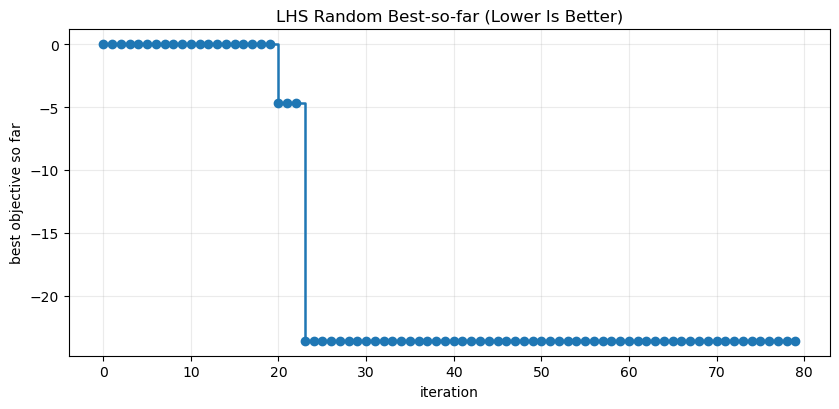

In [6]:
import matplotlib.pyplot as plt

if RUN_ONLINE and 'history_df' in globals() and not history_df.empty:
    plot_df = history_df.copy().sort_values('iteration')
    plot_df['best_so_far'] = pd.to_numeric(plot_df['best_so_far'], errors='coerce')
    finite_best = np.isfinite(plot_df['best_so_far'])

    if not finite_best.any():
        print('No finite best_so_far values yet.')
    else:
        fig, ax = plt.subplots(figsize=(8.5, 4.2))
        ax.plot(
            plot_df.loc[finite_best, 'iteration'],
            plot_df.loc[finite_best, 'best_so_far'],
            marker='o',
            lw=1.8,
            drawstyle='steps-post',
        )
        ax.set_title('LHS Random Best-so-far (Lower Is Better)')
        ax.set_xlabel('iteration')
        ax.set_ylabel('best objective so far')
        ax.grid(True, alpha=0.25)
        plt.tight_layout()
else:
    print('No history available yet. Run the experiment cell first.')


Compact LHS random campaign metrics:


,seed,run_id,method,status,best_objective,first_feasible_iteration,cache_hit_ratio,runtime_engine_sec,runtime_sim_sec,num_trials
0,0,lhs_online_general_seed0,lhs_random,completed,-25.141275,NaN,0.9875,2.612550,261.181061,80
1,1,lhs_online_general_seed1,lhs_random,completed,-19.161885,NaN,0.1500,2.616596,37766.801787,80
2,2,lhs_online_general_seed2,lhs_random,completed,-16.313817,NaN,0.1000,2.627790,49110.676843,80
3,3,lhs_online_general_seed3,lhs_random,completed,-9.847343,NaN,0.1375,2.535241,36469.737143,80
4,4,lhs_online_general_seed4,lhs_random,completed,-23.610561,None,0.1750,2.544871,35571.589094,80


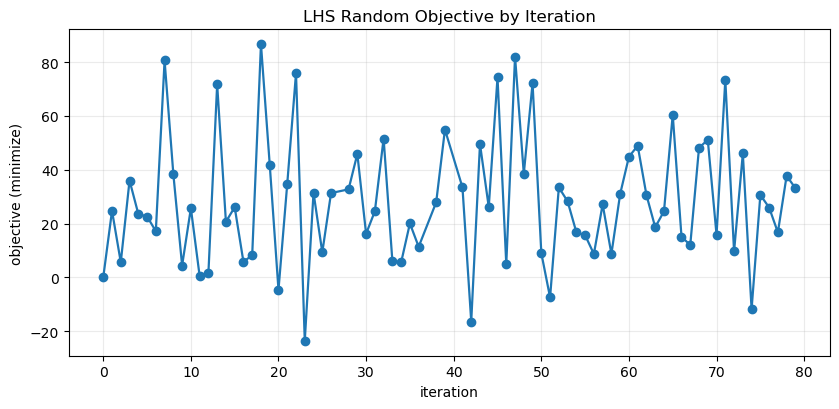

In [7]:
if RUN_ONLINE and 'history_df' in globals() and not history_df.empty:
    import matplotlib.pyplot as plt

    plot_df = history_df.copy().sort_values('iteration')
    plot_df['objective'] = pd.to_numeric(plot_df['objective'], errors='coerce')
    finite_obj = np.isfinite(plot_df['objective'])

    fig, ax = plt.subplots(figsize=(8.5, 4.2))
    if finite_obj.any():
        ax.plot(plot_df.loc[finite_obj, 'iteration'], plot_df.loc[finite_obj, 'objective'], marker='o', lw=1.6)
    ax.set_title('LHS Random Objective by Iteration')
    ax.set_xlabel('iteration')
    ax.set_ylabel('objective (minimize)')
    ax.grid(True, alpha=0.25)
    plt.tight_layout()

    if 'campaign_summary_df' in globals() and not campaign_summary_df.empty:
        cols = ['seed', 'run_id', 'method', 'status', 'best_objective', 'first_feasible_iteration', 'cache_hit_ratio', 'runtime_engine_sec', 'runtime_sim_sec', 'num_trials']
        print('Compact LHS random campaign metrics:')
        display(campaign_summary_df[cols])
else:
    print('No history available yet. Run the experiment cell first.')


,iteration,obj_min,obj_max,obj_mean,n
0,0,0.021325,62.909728,25.092644,5
1,1,14.658273,79.553398,38.987596,5
2,2,3.617281,42.409618,23.364230,5
3,3,26.301691,49.519853,36.596787,5
4,4,23.577600,80.080350,44.628529,5
5,5,-0.958946,61.710528,29.287474,4
6,6,-1.487287,106.312243,26.761215,5
7,7,1.100550,80.576579,29.057246,5
8,8,-1.889587,38.358235,17.680780,5
9,9,1.005400,100.765859,30.297286,5


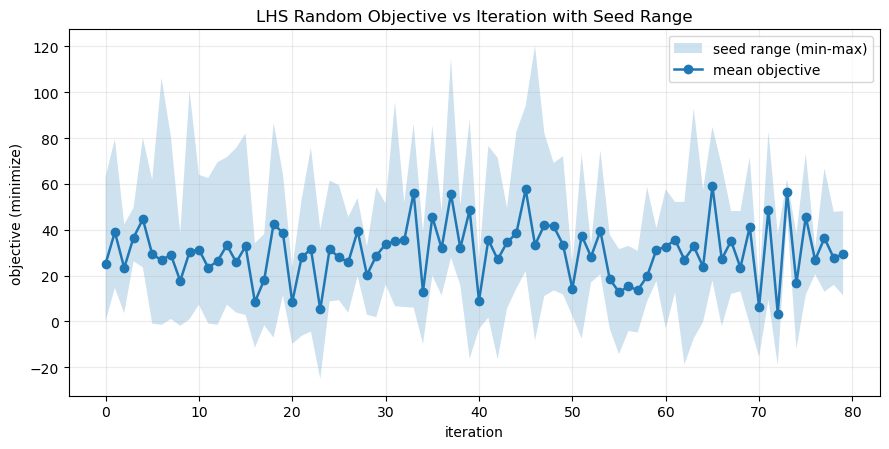

In [8]:
# Objective vs iteration with range band across configured seeds.
import json
import re
import matplotlib.pyplot as plt

if RUN_ONLINE:
    ckpt_paths = [checkpoint_for_seed(seed) for seed in SEEDS if checkpoint_for_seed(seed).exists()]
    if not ckpt_paths:
        print(f'No seed checkpoints found in {OUTPUT_DIR}')
    else:
        seed_pattern = re.compile(r'.*_seed(\d+)\.checkpoint\.json$')
        per_seed_histories: list[pd.DataFrame] = []

        for ckpt_path in ckpt_paths:
            payload = json.loads(ckpt_path.read_text())
            hist = pd.DataFrame(payload.get('history', []))
            if hist.empty or 'iteration' not in hist or 'objective' not in hist:
                continue

            seed_value = payload.get('seed')
            if seed_value is None:
                m = seed_pattern.match(ckpt_path.name)
                seed_value = int(m.group(1)) if m else None

            hist = hist.copy()
            hist['iteration'] = pd.to_numeric(hist['iteration'], errors='coerce')
            hist['objective'] = pd.to_numeric(hist['objective'], errors='coerce')
            hist = hist[np.isfinite(hist['iteration']) & np.isfinite(hist['objective'])]
            if hist.empty:
                continue

            hist['iteration'] = hist['iteration'].astype(int)
            hist['seed'] = seed_value
            per_seed_histories.append(hist[['seed', 'iteration', 'objective']])

        if not per_seed_histories:
            print('No valid objective/iteration history found in seed checkpoints.')
        else:
            all_hist_df = pd.concat(per_seed_histories, ignore_index=True)
            range_df = (
                all_hist_df
                .groupby('iteration', as_index=False)['objective']
                .agg(obj_min='min', obj_max='max', obj_mean='mean', n='count')
                .sort_values('iteration')
                .reset_index(drop=True)
            )

            fig, ax = plt.subplots(figsize=(9.0, 4.6))
            ax.fill_between(
                range_df['iteration'],
                range_df['obj_min'],
                range_df['obj_max'],
                alpha=0.22,
                label='seed range (min-max)',
            )
            ax.plot(
                range_df['iteration'],
                range_df['obj_mean'],
                lw=1.8,
                marker='o',
                label='mean objective',
            )
            ax.set_title('LHS Random Objective vs Iteration with Seed Range')
            ax.set_xlabel('iteration')
            ax.set_ylabel('objective (minimize)')
            ax.grid(True, alpha=0.25)
            ax.legend(loc='best')
            plt.tight_layout()

            display(range_df.head(20))
else:
    print('RUN_ONLINE is False; objective-range plot skipped.')


,iteration,best_min,best_max,best_mean,n
0,0,0.021325,62.909728,25.092644,5
1,1,0.021325,42.706699,19.149589,5
2,2,0.021325,27.176426,10.128100,5
3,3,0.021325,26.301691,9.953153,5
4,4,0.021325,26.301691,9.953153,5
5,5,-0.958946,18.375282,4.501026,5
6,6,-1.487287,8.193925,2.359086,5
7,7,-1.487287,8.193925,2.359086,5
8,8,-1.889587,8.193925,1.257713,5
9,9,-1.889587,8.193925,1.168755,5


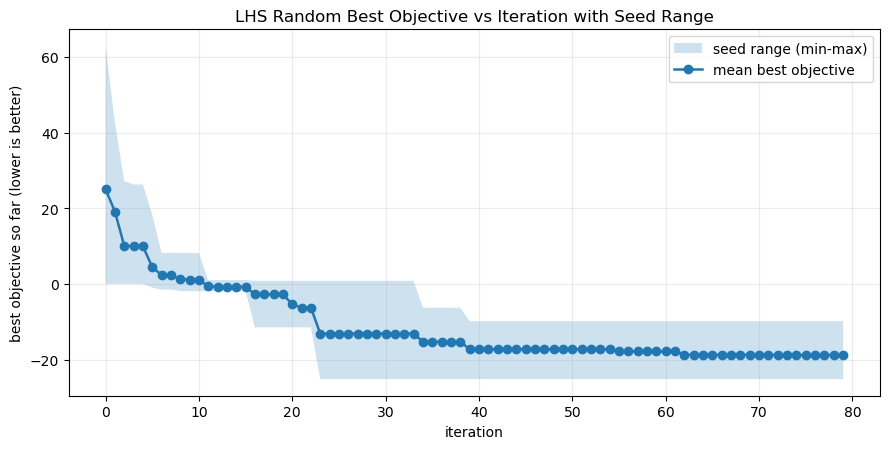

In [9]:
# Best objective (best-so-far) vs iteration with range band across configured seeds.
import json
import re
import matplotlib.pyplot as plt

if RUN_ONLINE:
    ckpt_paths = [checkpoint_for_seed(seed) for seed in SEEDS if checkpoint_for_seed(seed).exists()]
    if not ckpt_paths:
        print(f'No seed checkpoints found in {OUTPUT_DIR}')
    else:
        seed_pattern = re.compile(r'.*_seed(\d+)\.checkpoint\.json$')
        per_seed_best: list[pd.DataFrame] = []

        for ckpt_path in ckpt_paths:
            payload = json.loads(ckpt_path.read_text())
            hist = pd.DataFrame(payload.get('history', []))
            if hist.empty or 'iteration' not in hist:
                continue

            seed_value = payload.get('seed')
            if seed_value is None:
                m = seed_pattern.match(ckpt_path.name)
                seed_value = int(m.group(1)) if m else None

            hist = hist.copy()
            hist['iteration'] = pd.to_numeric(hist['iteration'], errors='coerce')

            if 'best_so_far' in hist:
                hist['best_so_far'] = pd.to_numeric(hist['best_so_far'], errors='coerce')
            elif 'objective' in hist:
                # Fallback: reconstruct best-so-far from objective when needed.
                hist['objective'] = pd.to_numeric(hist['objective'], errors='coerce')
                hist['best_so_far'] = hist['objective'].cummin()
            else:
                continue

            hist = hist[np.isfinite(hist['iteration']) & np.isfinite(hist['best_so_far'])]
            if hist.empty:
                continue

            hist['iteration'] = hist['iteration'].astype(int)
            hist['seed'] = seed_value
            per_seed_best.append(hist[['seed', 'iteration', 'best_so_far']])

        if not per_seed_best:
            print('No valid best objective history found in seed checkpoints.')
        else:
            best_all_df = pd.concat(per_seed_best, ignore_index=True)
            best_range_df = (
                best_all_df
                .groupby('iteration', as_index=False)['best_so_far']
                .agg(best_min='min', best_max='max', best_mean='mean', n='count')
                .sort_values('iteration')
                .reset_index(drop=True)
            )

            fig, ax = plt.subplots(figsize=(9.0, 4.6))
            ax.fill_between(
                best_range_df['iteration'],
                best_range_df['best_min'],
                best_range_df['best_max'],
                alpha=0.22,
                label='seed range (min-max)',
            )
            ax.plot(
                best_range_df['iteration'],
                best_range_df['best_mean'],
                marker='o',
                lw=1.8,
                label='mean best objective',
            )
            ax.set_title('LHS Random Best Objective vs Iteration with Seed Range')
            ax.set_xlabel('iteration')
            ax.set_ylabel('best objective so far (lower is better)')
            ax.grid(True, alpha=0.25)
            ax.legend(loc='best')
            plt.tight_layout()

            display(best_range_df.head(20))
else:
    print('RUN_ONLINE is False; best-objective range plot skipped.')
